# 02 — Data Preprocessing

## Purpose

This notebook establishes the train/validation protocol and examines conservative text representations for the 20 Newsgroups corpus. Reusable implementation lives in `src/topicsense/preprocessing/`; this notebook orchestrates it and records research observations.

The original raw JSONL dataset is read-only. This notebook does not overwrite, clean in place, or redistribute the raw messages.

## Methodological decisions

1. Preserve the official date-based training and test partitions.
2. Derive validation only from the official training partition.
3. Use a stratified group-aware split. Duplicate-connected records identified by the exact normalized-body audit and the MinHash/Jaccard near-duplicate audit must remain in the same fold.
4. Generate a second train/validation split after excluding the 10 substantive training records identified by the existing decontamination manifest. This supports the decontaminated-training sensitivity track without changing the official benchmark.
5. Keep the official test text and labels out of preprocessing exploration, vocabulary construction, fitting and model selection.
6. Compare full-message and message-body representations. Preserve headers, quotations, signatures, punctuation and case in the source; do not assume their removal improves classification.
7. Apply only deterministic Unicode and whitespace normalization in this phase. Stopword removal, stemming, lemmatization and punctuation deletion are not applied by default.
8. Any learned vocabulary, vectorizer, tokenizer vocabulary or feature weighting must be fitted on the training fold only in later modelling notebooks.

**Important:** the existing cross-partition contamination audit does not, by itself, protect a new train/validation split. This notebook therefore uses the within-training duplicate relationships to construct groups before splitting.

## 1. Imports and project configuration

Run JupyterLab from the repository root so the configuration and `src/` package can be resolved. If the notebook is opened from another working directory, set `PROJECT_ROOT` explicitly.

In [11]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

from topicsense.preprocessing import (
    create_preprocessing_splits,
    preprocess_text,
    tokenize_words,
)

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError(
        "Open this notebook with the repository root as the working directory."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))

CONFIG_PATH = PROJECT_ROOT / "configs" / "data.yaml"
with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = yaml.safe_load(file)

PROJECT_CONFIG = CONFIG["project"]
DATASET_CONFIG = CONFIG["dataset"]
SPLITTING_CONFIG = CONFIG["splitting"]

RANDOM_SEED = int(SPLITTING_CONFIG["random_seed"])
VALIDATION_SIZE = float(SPLITTING_CONFIG["validation_size"])

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset: {DATASET_CONFIG['display_name']}")
print(f"Validation target: {VALIDATION_SIZE:.0%}")
print(f"Random seed: {RANDOM_SEED}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Dataset: 20 Newsgroups
Validation target: 20%
Random seed: 42


## 2. Input artifacts and leakage-aware split generation

The split builder consumes:

- The immutable raw JSONL dataset.
- The normalized exact-body duplicate audit.
- The MinHash/Jaccard near-duplicate report.
- The decontaminated training ID manifest.

The official test partition is not supplied to the splitting algorithm. The output consists of record IDs and split metadata, not rewritten raw documents.

In [2]:
RAW_DATA_PATH = PROJECT_ROOT / DATASET_CONFIG["output_file"]
BODY_AUDIT_PATH = PROJECT_ROOT / SPLITTING_CONFIG["body_audit_report"]
LEAKAGE_REPORT_PATH = PROJECT_ROOT / SPLITTING_CONFIG["near_duplicate_report"]
DECONTAMINATED_IDS_PATH = PROJECT_ROOT / SPLITTING_CONFIG["decontaminated_train_ids"]
SPLIT_OUTPUT_DIR = PROJECT_ROOT / SPLITTING_CONFIG["output_dir"]

required_inputs = [
    RAW_DATA_PATH,
    BODY_AUDIT_PATH,
    LEAKAGE_REPORT_PATH,
    DECONTAMINATED_IDS_PATH,
]
missing_inputs = [path for path in required_inputs if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError(
        "Required phase-2 inputs are missing:\n"
        + "\n".join(str(path) for path in missing_inputs)
        + "\nRun the existing acquisition, leakage audit and contamination-manifest "
        "scripts before this notebook."
    )

SPLIT_RESULT = create_preprocessing_splits(
    raw_dataset_path=RAW_DATA_PATH,
    body_audit_path=BODY_AUDIT_PATH,
    leakage_report_path=LEAKAGE_REPORT_PATH,
    decontaminated_train_ids_path=DECONTAMINATED_IDS_PATH,
    output_dir=SPLIT_OUTPUT_DIR,
    validation_size=VALIDATION_SIZE,
    random_seed=RANDOM_SEED,
)

print("Split generation completed.")
print(f"Split artifacts: {SPLIT_OUTPUT_DIR}")

Split generation completed.
Split artifacts: /home/nkululekocyrilcele/projects/topicsense-nlp/data/interim/20newsgroups/splits


## 3. Split sizes and class distributions

`StratifiedGroupKFold` targets a 20% validation fold while keeping duplicate-connected documents together. Because groups can contain different numbers of documents, the realised validation fraction may differ slightly from exactly 20%. The realised counts and class distributions below are the authoritative outputs.


In [3]:
split_rows = []
for split_name, split_data in SPLIT_RESULT["splits"].items():
    split_rows.extend(
        [
            {
                "development track": split_name,
                "partition": "training",
                "documents": split_data["training_count"],
                "actual fraction": split_data["training_fraction_actual"],
                "groups": split_data["training_group_count"],
            },
            {
                "development track": split_name,
                "partition": "validation",
                "documents": split_data["validation_count"],
                "actual fraction": split_data["validation_fraction_actual"],
                "groups": split_data["validation_group_count"],
            },
        ]
    )

split_summary = pd.DataFrame(split_rows)
display(split_summary.style.format({"actual fraction": "{:.2%}"}))

print("Duplicate grouping diagnostics")
display(pd.Series(SPLIT_RESULT["grouping"], name="value").to_frame())

,development track,partition,documents,actual fraction,groups
0,official_training,training,9051,80.00%,8983
1,official_training,validation,2263,20.00%,2246
2,decontaminated_training,training,9042,79.99%,8974
3,decontaminated_training,validation,2262,20.01%,2245


Duplicate grouping diagnostics


,value
basis,[normalized exact message-body duplicate group...
exact_duplicate_links_considered,36
near_duplicate_links_considered,91
connected_component_count,11229
multi_document_component_count,79
largest_component_size,5


## 4. Split integrity checks

These assertions verify that:

- Training and validation record IDs do not overlap.
- Duplicate-connected groups do not cross the split boundary.
- Every class is represented in both partitions.
- The official test partition is not included in either development fold.
- The decontaminated split is built only after applying the pre-existing training exclusion manifest.


In [4]:
for split_name, split_data in SPLIT_RESULT["splits"].items():
    training_ids = set(split_data["training_record_ids"])
    validation_ids = set(split_data["validation_record_ids"])

    assert training_ids.isdisjoint(validation_ids)
    assert split_data["group_overlap_count"] == 0
    assert len(training_ids) == split_data["training_count"]
    assert len(validation_ids) == split_data["validation_count"]
    assert set(split_data["training_class_distribution"]) == set(
        split_data["validation_class_distribution"]
    )

    print(
        f"{split_name}: "
        f"{len(training_ids):,} training / "
        f"{len(validation_ids):,} validation; "
        f"group overlap = {split_data['group_overlap_count']}"
    )

RAW_MANIFEST_PATH = PROJECT_ROOT / DATASET_CONFIG["manifest_file"]
with RAW_MANIFEST_PATH.open("r", encoding="utf-8") as file:
    raw_manifest = json.load(file)

expected_test_count = raw_manifest["source_split_counts"]["test"]

assert SPLIT_RESULT["official_test_count"] == expected_test_count
print("Split integrity checks passed.")

official_training: 9,051 training / 2,263 validation; group overlap = 0
decontaminated_training: 9,042 training / 2,262 validation; group overlap = 0
Split integrity checks passed.


## 5. Preserve the three evaluation tracks

The official benchmark and clean-test sensitivity track use the same official-training development split. They differ only in the final evaluation IDs. The decontaminated-training sensitivity track uses its own split after removing the training records listed in the contamination manifest.

The test partitions remain held out. This notebook reports their sizes from the existing manifests but does not inspect their document text or use their labels.


In [ ]:
with (DECONTAMINATED_IDS_PATH).open("r", encoding="utf-8") as file:
    decontaminated_payload = json.load(file)

clean_test_ids_path = PROJECT_ROOT / SPLITTING_CONFIG["clean_test_ids"]
with clean_test_ids_path.open("r", encoding="utf-8") as file:
    clean_test_payload = json.load(file)

contamination_manifest_path = PROJECT_ROOT / SPLITTING_CONFIG["contamination_manifest"]
with contamination_manifest_path.open("r", encoding="utf-8") as file:
    contamination_manifest = json.load(file)

contamination_summary = contamination_manifest["summary"]
track_summary = pd.DataFrame(
    [
        {
            "evaluation track": "Official benchmark",
            "development documents": SPLIT_RESULT["splits"]["official_training"][
                "document_count"
            ],
            "evaluation documents": SPLIT_RESULT["official_test_count"],
            "policy": "Original official training and test partitions",
        },
        {
            "evaluation track": "Clean-test sensitivity",
            "development documents": SPLIT_RESULT["splits"]["official_training"][
                "document_count"
            ],
            "evaluation documents": contamination_summary["clean_test_document_count"],
            "policy": (
                "Original training; substantive exact-duplicate test records excluded"
            ),
        },
        {
            "evaluation track": "Decontaminated-training sensitivity",
            "development documents": SPLIT_RESULT["splits"]["decontaminated_training"][
                "document_count"
            ],
            "evaluation documents": SPLIT_RESULT["official_test_count"],
            "policy": "Substantive exact-duplicate training records excluded",
        },
    ]
)
display(track_summary)
print("Contamination audit summary:")
display(pd.Series(contamination_summary, name="value").to_frame())

## 6. Conservative text representations

The reusable preprocessing functions support two representations:

- `full_message`: complete original message, including headers and body.
- `message_body`: text after the first header/body separator, falling back to the full text when no separator exists.

The normalizer applies Unicode NFKC and whitespace normalization. Lowercasing is optional and disabled by default. It does not remove quotations, signatures, punctuation, numbers, URLs or stopwords.

The word tokenizer below is a lightweight descriptive utility for this notebook, not the tokenizer to be used for transformer models.


In [ ]:
def load_training_development_records(path: Path) -> dict[str, dict]:
    records = {}
    with path.open("r", encoding="utf-8") as file:
        for line in file:
            if not line.strip():
                continue
            record = json.loads(line)
            if record.get("source_split") != "train":
                continue
            record_id = record["record_id"]
            if record_id in records:
                raise ValueError(f"Duplicate record ID: {record_id}")
            records[record_id] = record
    return records


TRAINING_RECORDS = load_training_development_records(RAW_DATA_PATH)

official_split = SPLIT_RESULT["splits"]["official_training"]
development_ids = (
    official_split["training_record_ids"] + official_split["validation_record_ids"]
)
development_records = [TRAINING_RECORDS[record_id] for record_id in development_ids]

profile_rows = []
for record in development_records:
    full_text = preprocess_text(
        record["text"],
        representation="full_message",
        lowercase=False,
    )
    body_text = preprocess_text(
        record["text"],
        representation="message_body",
        lowercase=False,
    )
    profile_rows.append(
        {
            "record_id": record["record_id"],
            "label": record["label"],
            "partition": (
                "training"
                if record["record_id"] in set(official_split["training_record_ids"])
                else "validation"
            ),
            "full_message_characters": len(full_text),
            "message_body_characters": len(body_text),
            "full_message_tokens": len(tokenize_words(full_text)),
            "message_body_tokens": len(tokenize_words(body_text)),
        }
    )

profile = pd.DataFrame(profile_rows)
display(profile.head())
print(f"Development documents profiled: {len(profile):,}")

## 7. Representation-level descriptive statistics

These summaries compare document length and token counts for the official-training development data only. They are descriptive analyses; they do not fit a vocabulary, vectorizer or model.

In [7]:
representation_summary = (
    profile.groupby("partition")[
        [
            "full_message_characters",
            "message_body_characters",
            "full_message_tokens",
            "message_body_tokens",
        ]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)
display(representation_summary)

class_representation_summary = (
    profile.groupby("label")[["full_message_tokens", "message_body_tokens"]]
    .median()
    .sort_index()
)
display(class_representation_summary.head(20))

full_message_characters                  message_body_characters  \
                              mean  median      std                    mean   
partition                                                                     
training                   1888.39  1137.0  4118.48                 1699.99   
validation                 1794.30  1120.0  3528.11                 1605.40   

                           full_message_tokens                 \
           median      std                mean median     std   
partition                                                       
training    946.0  4111.30              325.81  189.0  806.07   
validation  929.0  3522.19              312.29  186.0  735.48   

           message_body_tokens                 
                          mean median     std  
partition                                      
training                296.82  160.0  805.09  
validation              283.20  158.0  734.79

,full_message_tokens,message_body_tokens
label,,
alt.atheism,223.5,193.5
comp.graphics,139.0,110.0
comp.os.ms-windows.misc,163.0,132.0
comp.sys.ibm.pc.hardware,165.5,133.0
comp.sys.mac.hardware,159.5,131.0
comp.windows.x,160.0,130.0
misc.forsale,119.0,88.0
rec.autos,188.0,162.5
rec.motorcycles,178.5,152.0


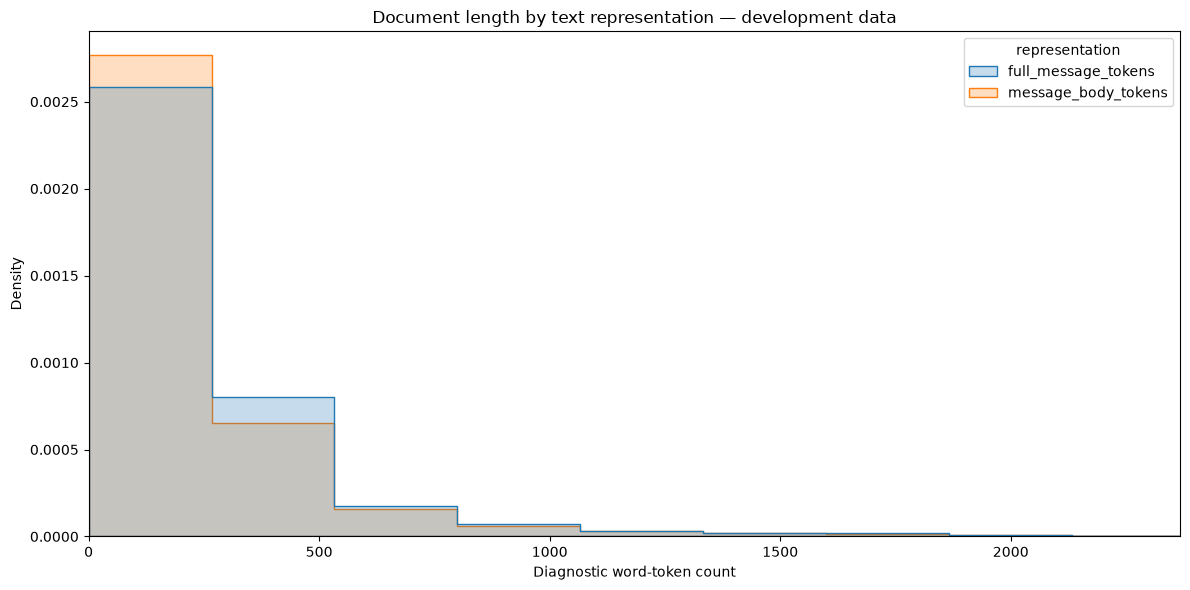

In [8]:
plot_data = profile.melt(
    id_vars=["partition"],
    value_vars=["full_message_tokens", "message_body_tokens"],
    var_name="representation",
    value_name="word-token count",
)
plt.figure(figsize=(12, 6))
sns.histplot(
    data=plot_data,
    x="word-token count",
    hue="representation",
    bins=60,
    element="step",
    stat="density",
    common_norm=False,
)
plt.xlim(
    0, profile[["full_message_tokens", "message_body_tokens"]].quantile(0.99).max()
)
plt.title("Document length by text representation — development data")
plt.xlabel("Diagnostic word-token count")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

## 8. Structural inspection without exposing message text

This section examines message structure without printing or embedding raw message content in notebook outputs. The sample is drawn only from the official training partition. It reports header-line and quoted-line counts, not the underlying text.

These indicators help describe the corpus while avoiding unnecessary reproduction of original messages in a notebook that may later be committed.

In [9]:
sample_ids = set(official_split["training_record_ids"])
sample_records = [
    record for record in development_records if record["record_id"] in sample_ids
][:100]

structural_rows = []
for record in sample_records:
    raw_text = record["text"]
    header_block, separator, body = raw_text.partition("\\n\\n")
    if not separator:
        header_block, body = "", raw_text

    structural_rows.append(
        {
            "record_id": record["record_id"],
            "label": record["label"],
            "header_line_count": len(header_block.splitlines()),
            "quoted_line_count": sum(
                line.lstrip().startswith(">") for line in body.splitlines()
            ),
            "full_message_characters": len(raw_text),
            "message_body_characters": len(body),
        }
    )

structural_profile = pd.DataFrame(structural_rows)
display(
    structural_profile.groupby("label")
    .agg(
        sample_count=("record_id", "count"),
        mean_header_lines=("header_line_count", "mean"),
        mean_quoted_lines=("quoted_line_count", "mean"),
    )
    .round(2)
)

,sample_count,mean_header_lines,mean_quoted_lines
label,,,
alt.atheism,6,0.0,10.33
comp.graphics,3,0.0,4.67
comp.os.ms-windows.misc,11,0.0,4.27
comp.sys.ibm.pc.hardware,1,0.0,0.00
comp.sys.mac.hardware,3,0.0,2.67
comp.windows.x,6,0.0,0.50
misc.forsale,6,0.0,1.17
rec.autos,9,0.0,5.22
rec.motorcycles,4,0.0,1.50


## 9. Persist the preprocessing profile

Only derived metadata and split IDs are written. The raw dataset is never modified. The split manifests are stored under `data/interim/`; the descriptive profile is stored under `results/`.

In [10]:
profile_output_dir = PROJECT_ROOT / "results" / "tables"
log_output_dir = PROJECT_ROOT / "results" / "logs"
profile_output_dir.mkdir(parents=True, exist_ok=True)
log_output_dir.mkdir(parents=True, exist_ok=True)

profile_csv_path = profile_output_dir / "preprocessing_profile.csv"
profile_json_path = log_output_dir / "preprocessing_profile_summary.json"

profile.to_csv(profile_csv_path, index=False)

profile_summary_payload = {
    "dataset": DATASET_CONFIG["name"],
    "random_seed": RANDOM_SEED,
    "validation_size_target": VALIDATION_SIZE,
    "text_preprocessing": {
        "unicode_normalization": "NFKC",
        "whitespace_normalization": True,
        "lowercase_default": False,
        "punctuation_removal": False,
        "stopword_removal": False,
        "stemming": False,
        "lemmatization": False,
        "representations_compared": ["full_message", "message_body"],
    },
    "development_documents_profiled": int(len(profile)),
    "profile_columns": list(profile.columns),
    "split_manifest": str(SPLIT_OUTPUT_DIR / "preprocessing_split_manifest.json"),
    "profile_csv": str(profile_csv_path),
}
profile_json_path.write_text(
    json.dumps(profile_summary_payload, indent=2, ensure_ascii=False) + "\\n",
    encoding="utf-8",
)

print(f"Saved profile: {profile_csv_path}")
print(f"Saved summary: {profile_json_path}")

Saved profile: /home/nkululekocyrilcele/projects/topicsense-nlp/results/tables/preprocessing_profile.csv
Saved summary: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/preprocessing_profile_summary.json


## 10. Interpretation and hand-off

### Decisions established in this notebook

- The raw dataset remains immutable.
- Official train/test boundaries are preserved.
- Validation is drawn only from official training data.
- Exact-body and reported near-duplicate relationships are grouped before splitting to reduce within-development leakage.
- The official and clean-test tracks share the same development split.
- The decontaminated-training track has a separate development split after applying the existing exact-duplicate exclusions.
- Full-message and message-body representations are retained as controlled alternatives.
- Text normalization is conservative and deterministic.

### Limitations

The near-duplicate detector is approximate and depends on the candidate pairs present in the audit report. Grouping connected components is intentionally conservative: transitive links can create larger groups and make exact stratification or a precise 80/20 ratio impossible. The realised split counts and distributions must therefore be reported rather than assuming an exact ratio.

The existing contamination sensitivity manifests remove substantive exact-body duplicates across the official train/test boundary. Near-duplicate pairs are not automatically removed from the evaluation tracks; they are grouped within the development split and remain a separately documented limitation for final evaluation.

### Next phase

Notebook 03 will establish classical baselines. Any learned vocabulary, CountVectorizer or TF-IDF transformation must be placed inside a scikit-learn pipeline and fitted on the training fold only. Validation will guide model selection; the official test partitions remain reserved for final evaluation.